[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/doomcodingbryan/STSCI4981/blob/main/notebooks/02_models.ipynb)

# 02: Does speed predict playing time beyond draft position?

This notebook only **reads** `data/combine_draft_outcomes_2016_2024.csv`. All cleaning lives in
`scripts/build_dataset.py`. See `CLAUDE.md` for the decisions behind every column used here.

The question Update 1 left open: faster players get more early playing time, but faster players are also
drafted earlier, and earlier picks play more regardless. So we ask whether 40 time still predicts playing
time **after** we control for where a player was taken.

Outcome: `y2_snap_share`, the share of possible team snaps a player was on the field for in their first two
NFL seasons, with missed games counted as 0.

Speed: `forty_z_pos`, the 40 time standardised within position group. It is a z-score, so a coefficient is
"change in snap share per one standard deviation of 40 time". **Negative means faster.** A negative
coefficient therefore means slower players play less.

Specialists (`pos_group == "ST"`) are excluded throughout.

In [1]:
# Colab bootstrap. On Colab this downloads the project so the data file is there.
# On your own machine it does nothing, so the notebook runs the same either way.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    REPO_DIR = "/content/STSCI4981"
    if not os.path.isdir(REPO_DIR):
        subprocess.run(
            ["git", "clone", "--depth", "1", "-q",
             "https://github.com/doomcodingbryan/STSCI4981.git", REPO_DIR],
            check=True)
    os.chdir(f"{REPO_DIR}/notebooks")
    print("Running in Colab, working from", os.getcwd())


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

df = pd.read_csv(ROOT / "data" / "combine_draft_outcomes_2016_2024.csv")
df = df[df["pos_group"] != "ST"].copy()

POS_ORDER = ["QB", "RB", "WR", "TE", "OL", "DL", "LB", "DB"]
df["pos_group"] = pd.Categorical(df["pos_group"], categories=POS_ORDER, ordered=True)

# Log of overall pick number. Pick 1 to pick 32 is a far bigger talent gap than pick 200 to pick 231,
# so the log scale matches how draft value actually falls off.
df["log_pick"] = np.log(df["draft_ovr"])

# Size-adjusted speed, standardised within position so it is on the same scale as forty_z_pos.
df["speed_score_z"] = df.groupby("pos_group", observed=True)["speed_score"].transform(
    lambda s: (s - s.mean()) / s.std())

# Complete cases on the two variables every model needs.
model_df = df.dropna(subset=["forty_z_pos", "y2_snap_share"]).copy()
drafted = model_df[model_df["drafted"]].copy()

print(f"all participants with a 40 time: {len(model_df)}")
print(f"of those, drafted:              {len(drafted)}")

all participants with a 40 time: 2429
of those, drafted:              1620


## 1. The main result

Three models, each with position-group fixed effects so players are only ever compared within their own
position. Standard errors are heteroskedasticity robust (HC3), because snap share is bounded at 0 and 1 and
its variance is far from constant.

1. **All participants.** The raw association, drafted and undrafted together.
2. **Drafted only.** Same model on drafted players, so the sample matches model 3.
3. **Drafted only, controlling for draft position.** The test that matters.

The number to watch is how much the speed coefficient shrinks between models 2 and 3.

In [3]:
m1 = smf.ols("y2_snap_share ~ forty_z_pos + C(pos_group)", data=model_df).fit(cov_type="HC3")
m2 = smf.ols("y2_snap_share ~ forty_z_pos + C(pos_group)", data=drafted).fit(cov_type="HC3")
m3 = smf.ols("y2_snap_share ~ forty_z_pos + log_pick + C(pos_group)", data=drafted).fit(cov_type="HC3")

def row(name, fit, n):
    return {
        "model": name,
        "n": n,
        "beta_speed": round(fit.params["forty_z_pos"], 4),
        "se": round(fit.bse["forty_z_pos"], 4),
        "p": round(fit.pvalues["forty_z_pos"], 4),
        "r2": round(fit.rsquared, 3),
    }

main = pd.DataFrame([
    row("1. all participants", m1, len(model_df)),
    row("2. drafted only", m2, len(drafted)),
    row("3. drafted, + log(pick)", m3, len(drafted)),
]).set_index("model")
main

,n,beta_speed,se,p,r2
model,,,,,
1. all participants,2429,-0.0759,0.0048,0.0000,0.106
2. drafted only,1620,-0.0517,0.0074,0.0000,0.058
"3. drafted, + log(pick)",1620,-0.0006,0.0063,0.9266,0.401


In [4]:
shrink = 100 * (1 - m3.params["forty_z_pos"] / m2.params["forty_z_pos"])
print(f"speed coefficient among drafted players:        {m2.params['forty_z_pos']:+.4f}")
print(f"after controlling for log(overall pick):        {m3.params['forty_z_pos']:+.4f}")
print(f"shrinkage:                                      {shrink:.0f}%")
print(f"coefficient on log(pick):                       {m3.params['log_pick']:+.4f} "
      f"(p = {m3.pvalues['log_pick']:.1e})")

speed coefficient among drafted players:        -0.0517
after controlling for log(overall pick):        -0.0006
shrinkage:                                      99%
coefficient on log(pick):                       -0.1805 (p = 1.6e-183)


## 2. The same test one position at a time

Pooled fixed effects assume speed matters equally everywhere. It almost certainly does not, so we refit
within each position group, drafted players only, before and after the draft control.

Read `pct_shrink` with care: where the coefficient changes sign (RB, WR, DB) the percentage is not meaningful, and the point is simply that no speed effect survives the draft control.


In [5]:
rows = []
for pos in POS_ORDER:
    g = drafted[drafted["pos_group"] == pos]
    before = smf.ols("y2_snap_share ~ forty_z_pos", data=g).fit(cov_type="HC3")
    after = smf.ols("y2_snap_share ~ forty_z_pos + log_pick", data=g).fit(cov_type="HC3")
    rows.append({
        "pos": pos,
        "n": len(g),
        "beta_before": before.params["forty_z_pos"],
        "p_before": before.pvalues["forty_z_pos"],
        "beta_after": after.params["forty_z_pos"],
        "p_after": after.pvalues["forty_z_pos"],
    })

by_pos = pd.DataFrame(rows).set_index("pos")
by_pos["pct_shrink"] = (100 * (1 - by_pos.beta_after / by_pos.beta_before)).round(0)
by_pos.round(4)

,n,beta_before,p_before,beta_after,p_after,pct_shrink
pos,,,,,,
QB,65,-0.0395,0.2510,-0.0040,0.8726,90.0
RB,142,-0.0040,0.8431,0.0199,0.2395,596.0
WR,227,-0.0501,0.0021,0.0218,0.1878,143.0
TE,92,-0.0578,0.0357,-0.0077,0.7568,87.0
OL,282,-0.1031,0.0001,-0.0190,0.4102,82.0
DL,309,-0.0301,0.0129,-0.0015,0.8713,95.0
LB,153,-0.0988,0.0001,-0.0054,0.7774,95.0
DB,350,-0.0384,0.0403,0.0101,0.5455,126.0


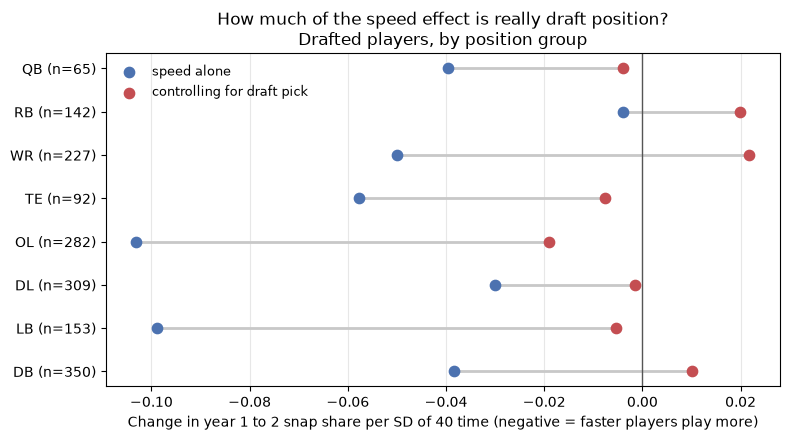

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(by_pos))[::-1]

# Dumbbell: the line is how much of the raw speed effect draft position absorbs.
ax.hlines(y, by_pos.beta_before, by_pos.beta_after, color="#C8C8C8", linewidth=2, zorder=1)
ax.scatter(by_pos.beta_before, y, s=55, color="#4C72B0", zorder=2, label="speed alone")
ax.scatter(by_pos.beta_after, y, s=55, color="#C44E52", zorder=2, label="controlling for draft pick")
ax.axvline(0, color="#555555", linewidth=1)

ax.set_yticks(y, [f"{p} (n={n})" for p, n in zip(by_pos.index, by_pos.n)])
ax.set_xlabel("Change in year 1 to 2 snap share per SD of 40 time (negative = faster players play more)")
ax.set_title("How much of the speed effect is really draft position?\nDrafted players, by position group")
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURES / "model_speed_coef_by_pos.png", dpi=300)
plt.show()

## 3. Which speed measure works best?

`forty_z_pos` is raw speed within position. `speed_score` is weight adjusted (wt x 200 / forty^4), which is
the measure scouts use to say a big player is fast *for their size*. Both are standardised within position,
so the coefficients are directly comparable.

In [7]:
measures = {}
for name, var in [("forty_z_pos", "forty_z_pos"), ("speed_score_z", "speed_score_z")]:
    g = drafted.dropna(subset=[var])
    a = smf.ols(f"y2_snap_share ~ {var} + C(pos_group)", data=g).fit(cov_type="HC3")
    b = smf.ols(f"y2_snap_share ~ {var} + log_pick + C(pos_group)", data=g).fit(cov_type="HC3")
    measures[name] = {
        "n": len(g),
        "beta_alone": round(a.params[var], 4),
        "p_alone": round(a.pvalues[var], 4),
        "beta_with_pick": round(b.params[var], 4),
        "p_with_pick": round(b.pvalues[var], 4),
        "r2_with_pick": round(b.rsquared, 3),
    }

pd.DataFrame(measures).T

,n,beta_alone,p_alone,beta_with_pick,p_with_pick,r2_with_pick
forty_z_pos,1620.0,-0.0517,0.0,-0.0006,0.9266,0.401
speed_score_z,1612.0,0.0616,0.0,0.0028,0.6585,0.401


## 4. Who skipped the 40, and does it bias us?

Caveat 1 in `CLAUDE.md`: missing drills are not random. Top prospects have the least to gain from running,
so if the players who skipped the 40 are better than the ones who ran it, dropping them understates how well
the best players do and biases the whole analysis.

In [8]:
drafted_all = df[df["drafted"]].copy()
drafted_all["ran_forty"] = drafted_all["forty_z_pos"].notna()

skip = drafted_all.groupby("ran_forty").agg(
    n=("player_name", "size"),
    mean_pick=("draft_ovr", "mean"),
    mean_y2_snap_share=("y2_snap_share", "mean"),
    pct_made_nfl=("made_nfl", "mean"),
).round(3)
skip.index = ["skipped the 40", "ran the 40"]

print(skip.to_string())
print()
# Round 1 is where skipping is most common, so check it on its own.
r1 = drafted_all[drafted_all["draft_round"] == 1]
print("round 1 only:")
print(r1.groupby("ran_forty")["y2_snap_share"].agg(["size", "mean"]).round(3).to_string())

                   n  mean_pick  mean_y2_snap_share  pct_made_nfl
skipped the 40   358    113.891               0.320         0.941
ran the 40      1620    118.572               0.314         0.957

round 1 only:
           size   mean
ran_forty             
False        57  0.629
True        223  0.613


## 5. Sensitivity check: drop the 2021 class

Caveat 2: the 2021 Combine was cancelled, so 2021 numbers are pro day times from a larger and more
self-selected pool. Pro day times run fast. If the main result depends on 2021, it is not a real result.

In [9]:
no_2021 = drafted[~drafted["pro_day_2021"]]
m3_no21 = smf.ols("y2_snap_share ~ forty_z_pos + log_pick + C(pos_group)",
                  data=no_2021).fit(cov_type="HC3")

pd.DataFrame([
    row("full sample", m3, len(drafted)),
    row("without 2021", m3_no21, len(no_2021)),
]).set_index("model")

,n,beta_speed,se,p,r2
model,,,,,
full sample,1620,-0.0006,0.0063,0.9266,0.401
without 2021,1427,0.0002,0.0069,0.9807,0.396


## 6. Results file for the write-up

Everything above, written to `reports/results_update2.md` so the update and the paper can quote numbers
without rerunning anything.

In [10]:
out = ROOT / "reports" / "results_update2.md"
with out.open("w") as f:
    f.write("# Update 2 model results\n\n")
    f.write("Generated by `notebooks/02_models.ipynb`. Do not edit by hand; rerun the notebook.\n\n")
    f.write("Outcome: y2_snap_share. Speed: forty_z_pos (within-position z-score, negative = faster).\n")
    f.write("All models include position-group fixed effects and HC3 robust standard errors.\n\n")
    f.write("## Main models\n\n" + main.to_markdown() + "\n\n")
    f.write(f"Speed coefficient shrinks {shrink:.0f}% once log(overall pick) is added.\n\n")
    f.write("## By position group (drafted only)\n\n" + by_pos.round(4).to_markdown() + "\n\n")
    f.write("## Speed measures compared\n\n" + pd.DataFrame(measures).T.to_markdown() + "\n\n")
    f.write("## Drafted players who skipped the 40\n\n" + skip.to_markdown() + "\n\n")
    f.write("## Sensitivity: 2021 pro day class removed\n\n")
    f.write(f"Speed coefficient {m3.params['forty_z_pos']:+.4f} (full) vs "
            f"{m3_no21.params['forty_z_pos']:+.4f} (without 2021), "
            f"n = {len(drafted)} vs {len(no_2021)}.\n")

print(out.read_text())

# Update 2 model results

Generated by `notebooks/02_models.ipynb`. Do not edit by hand; rerun the notebook.

Outcome: y2_snap_share. Speed: forty_z_pos (within-position z-score, negative = faster).
All models include position-group fixed effects and HC3 robust standard errors.

## Main models

| model                   |    n |   beta_speed |     se |      p |    r2 |
|:------------------------|-----:|-------------:|-------:|-------:|------:|
| 1. all participants     | 2429 |      -0.0759 | 0.0048 | 0      | 0.106 |
| 2. drafted only         | 1620 |      -0.0517 | 0.0074 | 0      | 0.058 |
| 3. drafted, + log(pick) | 1620 |      -0.0006 | 0.0063 | 0.9266 | 0.401 |

Speed coefficient shrinks 99% once log(overall pick) is added.

## By position group (drafted only)

| pos   |   n |   beta_before |   p_before |   beta_after |   p_after |   pct_shrink |
|:------|----:|--------------:|-----------:|-------------:|----------:|-------------:|
| QB    |  65 |       -0.0395 |     0.251  |    

## Notes and limitations to carry into the paper

- `y2_snap_share` is bounded between 0 and 1 with a large spike at exactly 0 (players who never played).
  OLS ignores both facts. A fractional logit or a two-part model is the right robustness check, and belongs
  in Update 3, not here.
- Draft position is a **post-treatment** control in one reading: teams partly draft players because they ran
  fast, so controlling for pick number removes some of speed's real effect. The honest claim is a bound.
  Model 2 is the upper bound on how much speed matters, model 3 is the lower bound.
- Complete-case only. Section 4 shows who that leaves out.
- Still open: the AV secondary outcome, the 2016 and `pfr_id_source` sensitivity checks, and the shuttle.